# Lab 4: TensorBoard (modified)

Karuniya Premnath, IE 7374 MLOps

Based on `Labs/Tensorflow_Labs/TensorBoard/Lab1.ipynb` from raminmohammadi/MLOps.
The original trains a one-layer model on made-up data (y = 0.5x + 2 + noise) and looks at the loss in TensorBoard.

What I changed:
- Real dataset: Forest Cover Type (54 features, 7 tree classes) instead of made-up data
- Five model configs compared with 3-fold cross-validation: optimizer and learning rate, then three class-weight settings for the rare tree types
- Early stopping decides how long each run trains (up to 100 epochs), instead of a fixed epoch count
- The best config is picked by **CV macro F1 only**. The test set is used once, at the very end, on the chosen model
- TensorBoard: scalars, a Custom Scalars dashboard with my own layout, weight histograms, HParams, a confusion matrix image, and Debugger V2
- Helper functions live in `lab_utils.py` and have unit tests in `tests/` (also run by GitHub Actions)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karunprem45/ml_tensorflow_lab4/blob/main/Lab4_TensorBoard.ipynb)

Run in Google Colab: Runtime > Run all. It takes about 10 minutes.
The badge always opens the latest version of this notebook from GitHub.

## 0. Setup

In [1]:
# Get lab_utils.py and the tests from my repo (only needed in Colab)
import os, sys, subprocess
if not os.path.exists("lab_utils.py"):
    if not os.path.exists("ml_tensorflow_lab4"):
        subprocess.run(["git", "clone", "-q", "https://github.com/karunprem45/ml_tensorflow_lab4.git"], check=True)
    sys.path.insert(0, "ml_tensorflow_lab4")
    REPO_DIR = "ml_tensorflow_lab4"
else:
    REPO_DIR = "."
print("repo folder:", REPO_DIR)

repo folder: .


In [2]:
%load_ext tensorboard
!rm -rf ./logs/

In [3]:
import os
# Hide TensorFlow's C++ log lines (harmless internal messages). Python errors still show as usual.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

from datetime import datetime
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorboard.plugins.hparams import api as hp
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import lab_utils as lu

keras.utils.set_random_seed(42)
# Deterministic kernels: rerunning on the same platform gives exactly the same numbers
tf.config.experimental.enable_op_determinism()
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Data

Forest Cover Type (UCI, loaded through scikit-learn): each row is a 30m x 30m patch of forest in Colorado,
described by elevation, slope, distance to water and roads, sunlight at different times of day,
wilderness area and soil type. The task is to predict which of 7 tree types covers the patch.

The full data has 581,012 rows. I take a stratified sample of 20,000 so the runs finish in a few minutes on Colab.
The classes are very unbalanced (Cottonwood/Willow is under 1%), so I use **macro F1** as the main metric,
because plain accuracy would look fine even if the rare classes were ignored.

In [4]:
X, y = lu.load_covtype(n_samples=20000)
print("X:", X.shape)
print(pd.Series(y).map(dict(enumerate(lu.CLASS_NAMES))).value_counts().to_string())

# Hold out 20% as the test set. It is not touched again until section 5.
X_train, X_test, y_train, y_test = lu.split_data(X, y, test_size=0.2)
print("\ntrain:", X_train.shape, " test:", X_test.shape)

X: (20000, 54)
Lodgepole Pine       9752
Spruce/Fir           7292
Ponderosa Pine       1231
Krummholz             706
Douglas-fir           598
Aspen                 327
Cottonwood/Willow      94

train: (16000, 54)  test: (4000, 54)


## 2. Configs and HParams setup

Five configs, in two groups:

1. **Optimizer and learning rate** (no class weights): SGD 0.01, Adam 0.001, Adam 0.01.
2. **Class weights for the rare classes**, on Adam 0.01: none, `sqrt` and `balanced`.
   `balanced` weights each class by `n_samples / (n_classes * count)`, so Cottonwood/Willow (under 1% of rows)
   gets weight 30.5 and Lodgepole Pine 0.29: one rare row counts about 100 times as much as a common one. `sqrt` uses the square root of each weight, a milder boost (about 10 times).

All configs use the same network (Dense 128 > Dropout 0.2 > Dense 64 > Dense 7 softmax).
Training runs for up to 100 epochs, and early stopping ends each run once validation loss stops improving.

This cell also writes the layout for TensorBoard's **Custom Scalars** dashboard (defined in `lab_utils.custom_scalars_layout`).


In [5]:
# name: (optimizer, learning rate, class weights)
CONFIGS = {
    # group 1: optimizer and learning rate
    "sgd_lr0.01":            ("sgd", 0.01, "none"),
    "adam_lr0.001":          ("adam", 0.001, "none"),
    "adam_lr0.01":           ("adam", 0.01, "none"),
    # group 2: class weights on Adam lr 0.01
    "adam_lr0.01_sqrt":      ("adam", 0.01, "sqrt"),
    "adam_lr0.01_balanced":  ("adam", 0.01, "balanced"),
}
MAX_EPOCHS = 100  # upper limit only; early stopping decides when each run ends
PATIENCE = 5      # epochs without a 0.001 drop in validation loss before stopping
BATCH = 256
N_FOLDS = 3
N_CLASSES = len(lu.CLASS_NAMES)

HP_OPTIMIZER = hp.HParam("optimizer", hp.Discrete(["sgd", "adam"]))
HP_LR = hp.HParam("learning_rate", hp.Discrete([0.001, 0.01]))
HP_CLASS_WEIGHT = hp.HParam("class_weight", hp.Discrete(["none", "sqrt", "balanced"]))

stamp = datetime.now().strftime("%Y%m%d-%H%M%S")
base_dir = f"logs/cv/{stamp}"

with tf.summary.create_file_writer(base_dir).as_default():
    hp.hparams_config(
        hparams=[HP_OPTIMIZER, HP_LR, HP_CLASS_WEIGHT],
        metrics=[hp.Metric("cv_macro_f1", display_name="CV macro F1"),
                 hp.Metric("cv_accuracy", display_name="CV accuracy")],
    )

# layout for the Custom Scalars dashboard: loss, learning rate, val macro F1 and accuracy charts
lu.write_custom_scalars_layout("logs")

sqrt_w = lu.class_weights_for("sqrt", y_train, N_CLASSES)
bal_w = lu.class_weights_for("balanced", y_train, N_CLASSES)
print("class weights on the full training set:   sqrt   balanced")
for c in range(N_CLASSES):
    print(f"  {lu.CLASS_NAMES[c]:<18} {sqrt_w[c]:20.2f} {bal_w[c]:9.2f}")


class weights on the full training set:   sqrt   balanced
  Spruce/Fir                         0.63      0.39
  Lodgepole Pine                     0.54      0.29
  Ponderosa Pine                     1.52      2.32
  Cottonwood/Willow                  5.52     30.48
  Aspen                              2.95      8.72
  Douglas-fir                        2.19      4.78
  Krummholz                          2.01      4.05


## 3. Cross-validation on the training set only

For each config and each of the 3 folds:
- the scaler and the class weights are computed from that fold's training part only (no leakage into the fold's validation part)
- TensorBoard logs loss, accuracy and weight histograms; my callback adds learning rate and validation macro F1
- early stopping watches the fold's validation loss and keeps the best weights

Each config's mean CV score is written to the HParams dashboard.


In [6]:
folds = lu.cv_folds(y_train, n_splits=N_FOLDS)
cv_results = []
stopped_early = 0

for name, (opt_name, lr, cw) in CONFIGS.items():
    fold_f1, fold_acc, fold_best, fold_ran = [], [], [], []
    for k, (tr_idx, va_idx) in enumerate(folds, start=1):
        X_tr, X_va = lu.scale(X_train[tr_idx], X_train[va_idx])
        y_tr, y_va = y_train[tr_idx], y_train[va_idx]
        weights = lu.class_weights_for(cw, y_tr, N_CLASSES)

        logdir = f"{base_dir}/{name}/fold{k}"
        model = lu.build_model(X_tr.shape[1], N_CLASSES, opt_name, lr)
        history = model.fit(
            X_tr, y_tr,
            validation_data=(X_va, y_va),
            epochs=MAX_EPOCHS, batch_size=BATCH, verbose=0,
            class_weight=weights,
            callbacks=[
                keras.callbacks.TensorBoard(log_dir=logdir, histogram_freq=1),
                keras.callbacks.LearningRateScheduler(lu.lr_schedule),
                keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, min_delta=1e-3,
                                              restore_best_weights=True),
                lu.make_custom_scalars_callback(logdir, X_va, y_va),
            ],
        )
        probs = model.predict(X_va, verbose=0)
        ran = len(history.history["loss"])
        best_epoch = int(np.argmin(history.history["val_loss"])) + 1
        stopped_early += ran < MAX_EPOCHS
        fold_f1.append(lu.macro_f1(y_va, probs))
        fold_acc.append(accuracy_score(y_va, probs.argmax(axis=1)))
        fold_best.append(best_epoch)
        fold_ran.append(ran)
        print(f"{name} fold {k}: macro F1 = {fold_f1[-1]:.4f}, accuracy = {fold_acc[-1]:.4f}, "
              f"best epoch {best_epoch}, stopped after {ran}")

    result = {
        "run": name, "optimizer": opt_name, "learning_rate": lr, "class_weight": cw,
        "cv_macro_f1": float(np.mean(fold_f1)), "cv_macro_f1_std": float(np.std(fold_f1)),
        "cv_accuracy": float(np.mean(fold_acc)), "best_epochs": int(round(np.mean(fold_best))),
        "epochs_run": float(np.mean(fold_ran)),
    }
    cv_results.append(result)

    # one HParams session per config, holding its mean CV scores
    with tf.summary.create_file_writer(f"{base_dir}/{name}").as_default():
        hp.hparams({HP_OPTIMIZER: opt_name, HP_LR: lr, HP_CLASS_WEIGHT: cw})
        tf.summary.scalar("cv_macro_f1", result["cv_macro_f1"], step=1)
        tf.summary.scalar("cv_accuracy", result["cv_accuracy"], step=1)

n_runs = len(CONFIGS) * N_FOLDS
print(f"\nEarly stopping ended {stopped_early} of {n_runs} runs before the {MAX_EPOCHS}-epoch limit.")


sgd_lr0.01 fold 1: macro F1 = 0.3910, accuracy = 0.7051, best epoch 68, stopped after 68


sgd_lr0.01 fold 2: macro F1 = 0.3741, accuracy = 0.6906, best epoch 71, stopped after 71


sgd_lr0.01 fold 3: macro F1 = 0.3536, accuracy = 0.7030, best epoch 71, stopped after 71


adam_lr0.001 fold 1: macro F1 = 0.5410, accuracy = 0.7598, best epoch 64, stopped after 64


adam_lr0.001 fold 2: macro F1 = 0.5574, accuracy = 0.7500, best epoch 50, stopped after 50


adam_lr0.001 fold 3: macro F1 = 0.5475, accuracy = 0.7654, best epoch 54, stopped after 54


... (5 outputs left out)

adam_lr0.01_sqrt fold 3: macro F1 = 0.6534, accuracy = 0.7680, best epoch 26, stopped after 31


adam_lr0.01_balanced fold 1: macro F1 = 0.5844, accuracy = 0.6760, best epoch 19, stopped after 24


adam_lr0.01_balanced fold 2: macro F1 = 0.5317, accuracy = 0.6499, best epoch 17, stopped after 22


adam_lr0.01_balanced fold 3: macro F1 = 0.5528, accuracy = 0.6790, best epoch 22, stopped after 27

Early stopping ended 15 of 15 runs before the 100-epoch limit.


## 4. Pick the best config by CV score

`select_best` only looks at `cv_macro_f1`. No test numbers exist at this point.

The three `adam_lr0.01*` rows differ only in class weights, so comparing them shows what the weights do on their own.

In [7]:
cv_df = pd.DataFrame(cv_results).sort_values("cv_macro_f1", ascending=False)
display(cv_df.round(4))

print("Class weights on Adam lr 0.01 (same model, same folds):")
for run in ["adam_lr0.01", "adam_lr0.01_sqrt", "adam_lr0.01_balanced"]:
    r = next(r for r in cv_results if r["run"] == run)
    print(f"  {r['class_weight']:<9} CV macro F1 {r['cv_macro_f1']:.4f}   CV accuracy {r['cv_accuracy']:.4f}")
print()

best = lu.select_best(cv_results, metric="cv_macro_f1")
print(f"Best config by CV macro F1: {best['run']} "
      f"({best['cv_macro_f1']:.4f} +/- {best['cv_macro_f1_std']:.4f}), "
      f"retraining for {best['best_epochs']} epochs")

,run,optimizer,learning_rate,class_weight,cv_macro_f1,cv_macro_f1_std,cv_accuracy,best_epochs,epochs_run
2,adam_lr0.01,adam,0.010,none,0.6708,0.0098,0.7958,31,33.6667
3,adam_lr0.01_sqrt,adam,0.010,sqrt,0.6478,0.0098,0.7614,23,28.0000
4,adam_lr0.01_balanced,adam,0.010,balanced,0.5563,0.0217,0.6683,19,24.3333
1,adam_lr0.001,adam,0.001,none,0.5486,0.0067,0.7584,56,56.0000
0,sgd_lr0.01,sgd,0.010,none,0.3729,0.0153,0.6996,70,70.0000


Class weights on Adam lr 0.01 (same model, same folds):
  none      CV macro F1 0.6708   CV accuracy 0.7958
  sqrt      CV macro F1 0.6478   CV accuracy 0.7614
  balanced  CV macro F1 0.5563   CV accuracy 0.6683

Best config by CV macro F1: adam_lr0.01 (0.6708 +/- 0.0098), retraining for 31 epochs


## 5. Retrain the chosen config and test it once

The chosen config is retrained on the full training set (scaler fit on the full training set),
for the average best epoch found by early stopping in CV, with the same class-weight setting. Then it is evaluated on the test set **once**.
The confusion matrix is logged to TensorBoard's Images tab.

Test macro F1: 0.6916
Test accuracy: 0.8093

                   precision    recall  f1-score   support

       Spruce/Fir       0.82      0.79      0.80      1458
   Lodgepole Pine       0.83      0.87      0.84      1951
   Ponderosa Pine       0.75      0.82      0.78       246
Cottonwood/Willow       0.62      0.53      0.57        19
            Aspen       0.61      0.42      0.50        65
      Douglas-fir       0.57      0.53      0.55       120
        Krummholz       0.88      0.73      0.80       141

         accuracy                           0.81      4000
        macro avg       0.73      0.67      0.69      4000
     weighted avg       0.81      0.81      0.81      4000



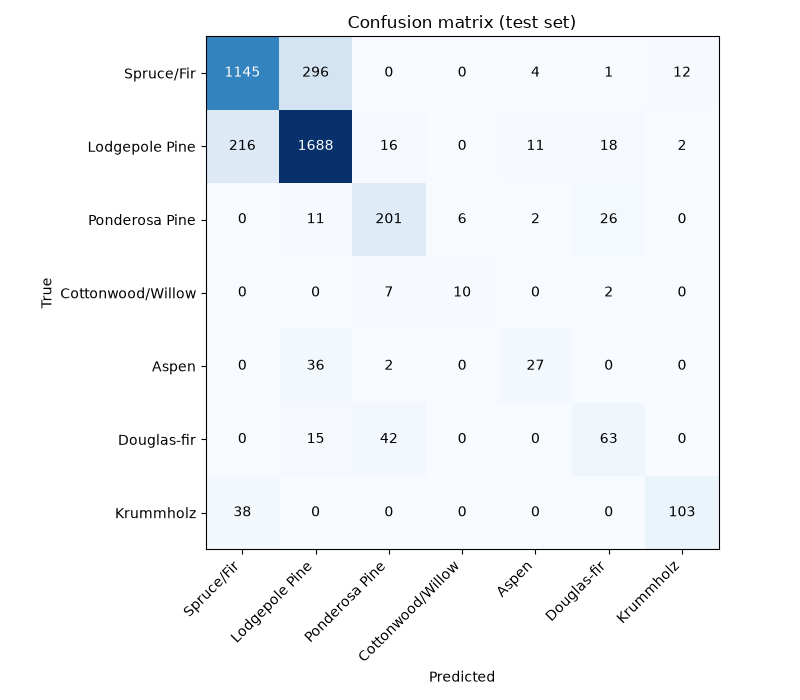

In [8]:
X_train_s, X_test_s = lu.scale(X_train, X_test)

final_dir = f"logs/final/{best['run']}"
final_weights = lu.class_weights_for(best["class_weight"], y_train, N_CLASSES)
final_model = lu.build_model(X_train_s.shape[1], N_CLASSES, best["optimizer"], best["learning_rate"])
final_model.fit(
    X_train_s, y_train,
    epochs=best["best_epochs"], batch_size=BATCH, verbose=0,
    class_weight=final_weights,
    callbacks=[
        keras.callbacks.TensorBoard(log_dir=final_dir, histogram_freq=1),
        keras.callbacks.LearningRateScheduler(lu.lr_schedule),
    ],
)

test_probs = final_model.predict(X_test_s, verbose=0)
test_pred = test_probs.argmax(axis=1)
print(f"Test macro F1: {lu.macro_f1(y_test, test_probs):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, test_pred):.4f}\n")
print(classification_report(y_test, test_pred, target_names=lu.CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_test, test_pred, labels=range(len(lu.CLASS_NAMES)))
fig = lu.confusion_matrix_figure(cm, lu.CLASS_NAMES)
with tf.summary.create_file_writer(final_dir + "/images").as_default():
    tf.summary.image("confusion_matrix_test", lu.figure_to_image(fig), step=0)

from IPython.display import Image
Image(lu.figure_to_png_bytes(fig))

## 6. Debugger V2: making a model fail on purpose

The original lab turns on the debugger, but its model trains fine, so there is nothing to find.
Here I train on **unscaled** features (elevation is in the thousands) with a high SGD learning rate (0.5),
which makes the loss turn into NaN in the first epoch. Debugger V2 then shows NaN/Inf alerts.
(With 0.1 the loss only spikes and then recovers, so there is nothing for the debugger to catch.)
The debugger is only on for this cell because it slows training a lot.
The random seed is reset first, so the broken model always starts from the same weights no matter how many models were trained above.

In [9]:
tf.debugging.experimental.enable_dump_debug_info(
    "logs/debugger", tensor_debug_mode="FULL_HEALTH", circular_buffer_size=-1
)

keras.utils.set_random_seed(42)  # same starting weights on every run
bad_model = lu.build_model(X_train.shape[1], len(lu.CLASS_NAMES), "sgd", 0.5)
bad_history = bad_model.fit(X_train[:2000], y_train[:2000], epochs=3, batch_size=64, verbose=1)
print("final loss:", bad_history.history["loss"][-1])

tf.debugging.experimental.disable_dump_debug_info()

INFO:tensorflow:Enabled dumping callback in thread MainThread (dump root: logs/debugger, tensor debug mode: FULL_HEALTH)


Epoch 1/3


 1/32 ━━━━━━━━━━━━━━━━━━━━ 16s 518ms/step - accuracy: 0.1094 - loss: 414.2224

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3745 - loss: nan        


Epoch 2/3


 1/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3750 - loss: nan

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3720 - loss: nan


Epoch 3/3


 1/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3750 - loss: nan

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3720 - loss: nan


final loss: nan
INFO:tensorflow:Disabled dumping callback in thread MainThread (dump root: logs/debugger)


## 7. Unit tests

In [10]:
!pip -q install pytest
!python -m pytest -v {REPO_DIR}/tests

============================= test session starts ==============================
platform darwin -- Python 3.11.18, pytest-9.2.0, pluggy-1.7.0 -- python
cachedir: .pytest_cache
rootdir: .C
plugins: platformdirs-4.14.5
collecting ... 

collected 16 items                                                             

tests/test_lab_utils.py::test_split_sizes_and_no_overlap PASSED          [  6%]
tests/test_lab_utils.py::test_split_is_stratified PASSED                 [ 12%]
tests/test_lab_utils.py::test_scale_fits_on_first_array_only PASSED      [ 18%]
tests/test_lab_utils.py::test_cv_folds_cover_every_row_once PASSED       [ 25%]
tests/test_lab_utils.py::test_lr_schedule PASSED                         [ 31%]
tests/test_lab_utils.py::test_macro_f1_perfect_and_wrong PASSED          [ 37%]
tests/test_lab_utils.py::test_select_best_uses_cv_not_test PASSED        [ 43%]
tests/test_lab_utils.py::test_select_best_empty_raises PASSED            [ 50%]
tests/test_lab_utils.py::test_confusion_matrix_figure_makes_png 

PASSED   [ 56%]
tests/test_lab_utils.py::test_balanced_class_weights_favour_rare_classes PASSED [ 62%]
tests/test_lab_utils.py::test_balanced_class_weights_equal_classes_and_missing_class PASSED [ 68%]
tests/test_lab_utils.py::test_sqrt_weights_are_milder_than_balanced PASSED [ 75%]
tests/test_lab_utils.py::test_custom_scalars_layout_covers_every_logged_tag 

PASSED [ 81%]
tests/test_lab_utils.py::test_write_custom_scalars_layout_creates_event_file 

PASSED [ 87%]
tests/test_lab_utils.py::test_build_model_output_shape_and_probabilities 

PASSED [ 93%]
tests/test_lab_utils.py::test_build_model_rejects_unknown_optimizer PASSED [100%]

============================== 16 passed in 3.47s ==============================


## 8. TensorBoard

- **Scalars / Time Series**: loss and accuracy for every config and fold; `learning_rate` and `val_macro_f1` under the `custom` runs
- **Custom Scalars**: my own layout (two groups, four charts) that puts one tag from every run on the same axes: train/validation loss, learning rate, validation macro F1, train/validation accuracy
- **Graphs**: pick **Conceptual graph** to see the model layers (Keras 3 writes only the Keras-level graph, so Op graph stays empty)
- **Histograms / Distributions**: weights changing over epochs
- **HParams**: the five configs side by side (optimizer, learning rate, class weights) with their CV scores (table view and parallel coordinates view)
- **Images**: test-set confusion matrix of the chosen model

Debugger V2 only reads debugger data that sits directly in `--logdir`, so it needs its own TensorBoard
pointed at `logs/debugger` (second cell below). It shows the NaN/Inf alerts from section 6.

In [ ]:
%tensorboard --logdir logs/

In [ ]:
%tensorboard --logdir logs/debugger --port 6007